In [1]:

# Step 8.1: Install and initialize ADWIN

%pip install river

from river.drift import ADWIN

# Initialize ADWIN detector
adwin = ADWIN(delta=0.002)

print("ADWIN initialized successfully.")
print("Delta:", adwin.delta)


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


ADWIN initialized successfully.
Delta: 0.002


In [2]:

# Step 8.2: Load dataset and trained iTransformer

import os
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from river.drift import ADWIN

# Set random seed
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")

# Load dataset
data = joblib.load("Dataset/cycle_time_data.joblib")

Xraw = np.asarray(data["Xraw"], dtype=np.float32)
yraw = np.asarray(data["yraw"], dtype=np.float32).reshape(-1, 1)

train_end = data["train_end"]
window = data["window"]

stable = data["stable"]
drift = data["drift"]
recovery = data["recovery"]

# Scale using training observations only
scaler_X = StandardScaler()
scaler_y = StandardScaler()

scaler_X.fit(Xraw[:train_end])
scaler_y.fit(yraw[:train_end])

X_scaled = scaler_X.transform(Xraw)
y_scaled = scaler_y.transform(yraw)

print("Dataset loaded successfully.")
print("X shape:", X_scaled.shape)
print("y shape:", y_scaled.shape)
print("Window size:", window)
print("Training end:", train_end)

# Initialize ADWIN
adwin = ADWIN(delta=0.002)

print("\nADWIN initialized successfully.")

# Check saved model
model_path = "Results/iTransformer/itransformer_model.pth"

print("Saved model exists:", os.path.exists(model_path))


Dataset loaded successfully.
X shape: (995, 5)
y shape: (995, 1)
Window size: 10
Training end: 400

ADWIN initialized successfully.
Saved model exists: True


In [3]:

# Step 8.3: Load trained iTransformer

class iTransformer(nn.Module):
    def __init__(
        self,
        seq_len=10,
        num_features=5,
        d_model=32,
        n_heads=4,
        n_layers=2,
        dropout=0.1
    ):
        super().__init__()

        self.embedding = nn.Linear(seq_len, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=64,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers,
            enable_nested_tensor=False
        )

        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(num_features * d_model, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.embedding(x)
        x = self.encoder(x)
        return self.head(x).squeeze(-1)


# Create model with identical architecture
model = iTransformer(
    seq_len=window,
    num_features=X_scaled.shape[1]
).to(device)

# Load saved trained weights
model.load_state_dict(
    torch.load(
        model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Trained iTransformer loaded successfully.")

print(
    "Total parameters:",
    sum(p.numel() for p in model.parameters())
)

# Test one prediction using observations 390-399
sample = torch.tensor(
    X_scaled[390:400],
    dtype=torch.float32
).unsqueeze(0).to(device)

with torch.no_grad():
    prediction_scaled = model(sample).cpu().numpy()

prediction = scaler_y.inverse_transform(
    prediction_scaled.reshape(-1, 1)
).flatten()[0]

print("\nFirst test observation index:", train_end)
print("Actual cycle time:", float(yraw[train_end, 0]))
print("Predicted cycle time:", float(prediction))


Trained iTransformer loaded successfully.
Total parameters: 27809

First test observation index: 400
Actual cycle time: 87.0
Predicted cycle time: 76.34188079833984


In [4]:

# Step 8.4: Sequential prediction and ADWIN detection

from river.drift import ADWIN

# Initialize ADWIN
adwin = ADWIN(delta=0.002)

predictions = []
actual_values = []
absolute_errors = []
drift_points = []

# Keep the model fixed during detection
model.eval()

for i in range(train_end, len(X_scaled)):

    # Previous 10 observations
    X_window = X_scaled[i-window:i]

    X_tensor = torch.tensor(
        X_window,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    # Predict before observing current target
    with torch.no_grad():
        pred_scaled = model(X_tensor).cpu().numpy()

    pred = scaler_y.inverse_transform(
        pred_scaled.reshape(-1, 1)
    )[0, 0]

    actual = float(yraw[i, 0])

    # Calculate prediction error
    error = abs(actual - pred)

    predictions.append(pred)
    actual_values.append(actual)
    absolute_errors.append(error)

    # Update ADWIN after observing true value
    adwin.update(error)

    if adwin.drift_detected:
        drift_points.append(i)
        print(f"ADWIN drift detected at observation {i}")

print("\nDetection completed.")
print("Total drift detections:", len(drift_points))
print("Detected points:", drift_points)

# Save detection results
os.makedirs("Results/iTransformer_ADWIN", exist_ok=True)

detection_df = pd.DataFrame({
    "Index": range(train_end, len(X_scaled)),
    "Actual": actual_values,
    "Predicted": predictions,
    "Absolute_Error": absolute_errors
})

detection_df["Drift_Detected"] = (
    detection_df["Index"].isin(drift_points)
)

detection_df.to_csv(
    "Results/iTransformer_ADWIN/drift_detection.csv",
    index=False
)

print("Detection results saved successfully.")


ADWIN drift detected at observation 623
ADWIN drift detected at observation 879

Detection completed.
Total drift detections: 2
Detected points: [623, 879]
Detection results saved successfully.


In [5]:

# Step 9.1: Prepare adaptive iTransformer

import copy

# Create a separate adaptive model
adaptive_model = copy.deepcopy(model).to(device)

adaptive_model.eval()

# Adaptive learning parameters
adaptive_learning_rate = 0.0001
fine_tune_epochs = 10
adaptation_window = 100
batch_size = 16

# Initialize a fresh ADWIN detector
adaptive_adwin = ADWIN(delta=0.002)

# Storage for online evaluation
adaptive_predictions = []
adaptive_actuals = []
adaptive_errors = []
adaptive_drift_points = []

print("Adaptive iTransformer initialized successfully.")

print("\nAdaptation configuration:")
print("Learning rate:", adaptive_learning_rate)
print("Fine-tuning epochs:", fine_tune_epochs)
print("Adaptation window:", adaptation_window)
print("Batch size:", batch_size)

# Confirm same initial model weights
same_weights = all(
    torch.equal(
        p1, p2
    )
    for p1, p2 in zip(
        model.parameters(),
        adaptive_model.parameters()
    )
)

print("\nInitial model weights identical:", same_weights)


Adaptive iTransformer initialized successfully.

Adaptation configuration:
Learning rate: 0.0001
Fine-tuning epochs: 10
Adaptation window: 100
Batch size: 16

Initial model weights identical: True


In [6]:

# Step 9.2: Adaptive iTransformer + ADWIN

from torch.utils.data import TensorDataset, DataLoader
import time

def fine_tune_model(model, current_index):
    """
    Fine-tune using only observations available
    up to and including current_index.
    """

    start = max(
        window,
        current_index - adaptation_window + 1
    )

    X_recent = []
    y_recent = []

    for j in range(start, current_index + 1):
        X_recent.append(X_scaled[j-window:j])
        y_recent.append(y_scaled[j, 0])

    X_recent = torch.tensor(
        np.array(X_recent),
        dtype=torch.float32
    )

    y_recent = torch.tensor(
        np.array(y_recent),
        dtype=torch.float32
    )

    dataset = TensorDataset(X_recent, y_recent)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=adaptive_learning_rate
    )

    criterion = nn.MSELoss()

    model.train()

    for epoch in range(fine_tune_epochs):
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, y_batch)
            loss.backward()
            optimizer.step()

    model.eval()


# Reset experiment state
adaptive_model.load_state_dict(
    torch.load(
        model_path,
        map_location=device,
        weights_only=True
    )
)

adaptive_model.eval()
adaptive_adwin = ADWIN(delta=0.002)

adaptive_predictions = []
adaptive_actuals = []
adaptive_errors = []
adaptive_drift_points = []

start_time = time.time()

for i in range(train_end, len(X_scaled)):

    # Predict using previous observations only
    X_window = X_scaled[i-window:i]

    X_tensor = torch.tensor(
        X_window,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    adaptive_model.eval()

    with torch.no_grad():
        pred_scaled = adaptive_model(
            X_tensor
        ).cpu().numpy().reshape(-1, 1)

    pred = scaler_y.inverse_transform(
        pred_scaled
    )[0, 0]

    # Actual value becomes available after prediction
    actual = float(yraw[i, 0])
    error = abs(actual - pred)

    adaptive_predictions.append(pred)
    adaptive_actuals.append(actual)
    adaptive_errors.append(error)

    # Monitor errors for drift
    adaptive_adwin.update(error)

    if adaptive_adwin.drift_detected:

        adaptive_drift_points.append(i)

        print(
            f"Drift detected at {i}. "
            "Fine-tuning model..."
        )

        fine_tune_model(
            adaptive_model,
            current_index=i
        )

        print("Fine-tuning completed.")

adaptive_time = time.time() - start_time

print("\nAdaptive forecasting completed.")
print("Drift points:", adaptive_drift_points)
print("Total adaptations:", len(adaptive_drift_points))
print(f"Execution time: {adaptive_time:.2f} seconds")

# Save adaptive predictions
os.makedirs("Results/iTransformer_ADWIN", exist_ok=True)

adaptive_results_df = pd.DataFrame({
    "Index": np.arange(train_end, len(X_scaled)),
    "Actual": adaptive_actuals,
    "Predicted": adaptive_predictions,
    "Absolute_Error": adaptive_errors
})

adaptive_results_df.to_csv(
    "Results/iTransformer_ADWIN/adaptive_predictions.csv",
    index=False
)

# Save updated model
torch.save(
    adaptive_model.state_dict(),
    "Results/iTransformer_ADWIN/adaptive_model.pth"
)

print("Adaptive results saved successfully.")


Drift detected at 623. Fine-tuning model...
Fine-tuning completed.
Drift detected at 879. Fine-tuning model...
Fine-tuning completed.

Adaptive forecasting completed.
Drift points: [623, 879]
Total adaptations: 2
Execution time: 5.18 seconds
Adaptive results saved successfully.


In [7]:

# Step 9.3: Compare baseline and adaptive iTransformer

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load baseline predictions
baseline_df = pd.read_csv(
    "Results/iTransformer/predictions.csv"
)

# Load adaptive predictions
adaptive_df = pd.read_csv(
    "Results/iTransformer_ADWIN/adaptive_predictions.csv"
)

# Merge using observation index
comparison_df = baseline_df.merge(
    adaptive_df[["Index", "Predicted"]],
    on="Index",
    suffixes=("_Baseline", "_Adaptive"),
    validate="one_to_one"
)

assert len(comparison_df) == 595
assert comparison_df["Index"].is_unique

def calculate_metrics(df, start, end):
    mask = df["Index"] >= start

    if end is not None:
        mask &= df["Index"] < end

    subset = df.loc[mask]
    actual = subset["Actual"]

    results = {}

    for name, column in [
        ("Baseline", "Predicted_Baseline"),
        ("Adaptive", "Predicted_Adaptive")
    ]:
        pred = subset[column]

        results[name + "_MAE"] = mean_absolute_error(
            actual, pred
        )

        results[name + "_RMSE"] = np.sqrt(
            mean_squared_error(actual, pred)
        )

    return results

periods = {
    "Stable": stable,
    "Drift": drift,
    "Recovery": recovery,
    "Overall": (train_end, None)
}

rows = []

for period, (start, end) in periods.items():
    metrics = calculate_metrics(
        comparison_df, start, end
    )

    rows.append({
        "Period": period,
        **metrics
    })

comparison_results = pd.DataFrame(rows)

# Positive improvement means adaptive is better
comparison_results["MAE_Improvement_%"] = (
    (
        comparison_results["Baseline_MAE"]
        - comparison_results["Adaptive_MAE"]
    )
    / comparison_results["Baseline_MAE"]
) * 100

comparison_results = comparison_results.round(3)

print("iTransformer vs iTransformer + ADWIN")
display(comparison_results)

comparison_results.to_csv(
    "Results/iTransformer_ADWIN/model_comparison.csv",
    index=False
)

print("Comparison saved successfully.")


iTransformer vs iTransformer + ADWIN


,Period,Baseline_MAE,Baseline_RMSE,Adaptive_MAE,Adaptive_RMSE,MAE_Improvement_%
0,Stable,26.743,32.507,26.743,32.507,-0.000
1,Drift,59.961,72.121,52.155,61.676,13.019
2,Recovery,33.604,39.243,31.062,36.777,7.564
3,Overall,40.158,51.071,36.700,45.575,8.609


Comparison saved successfully.


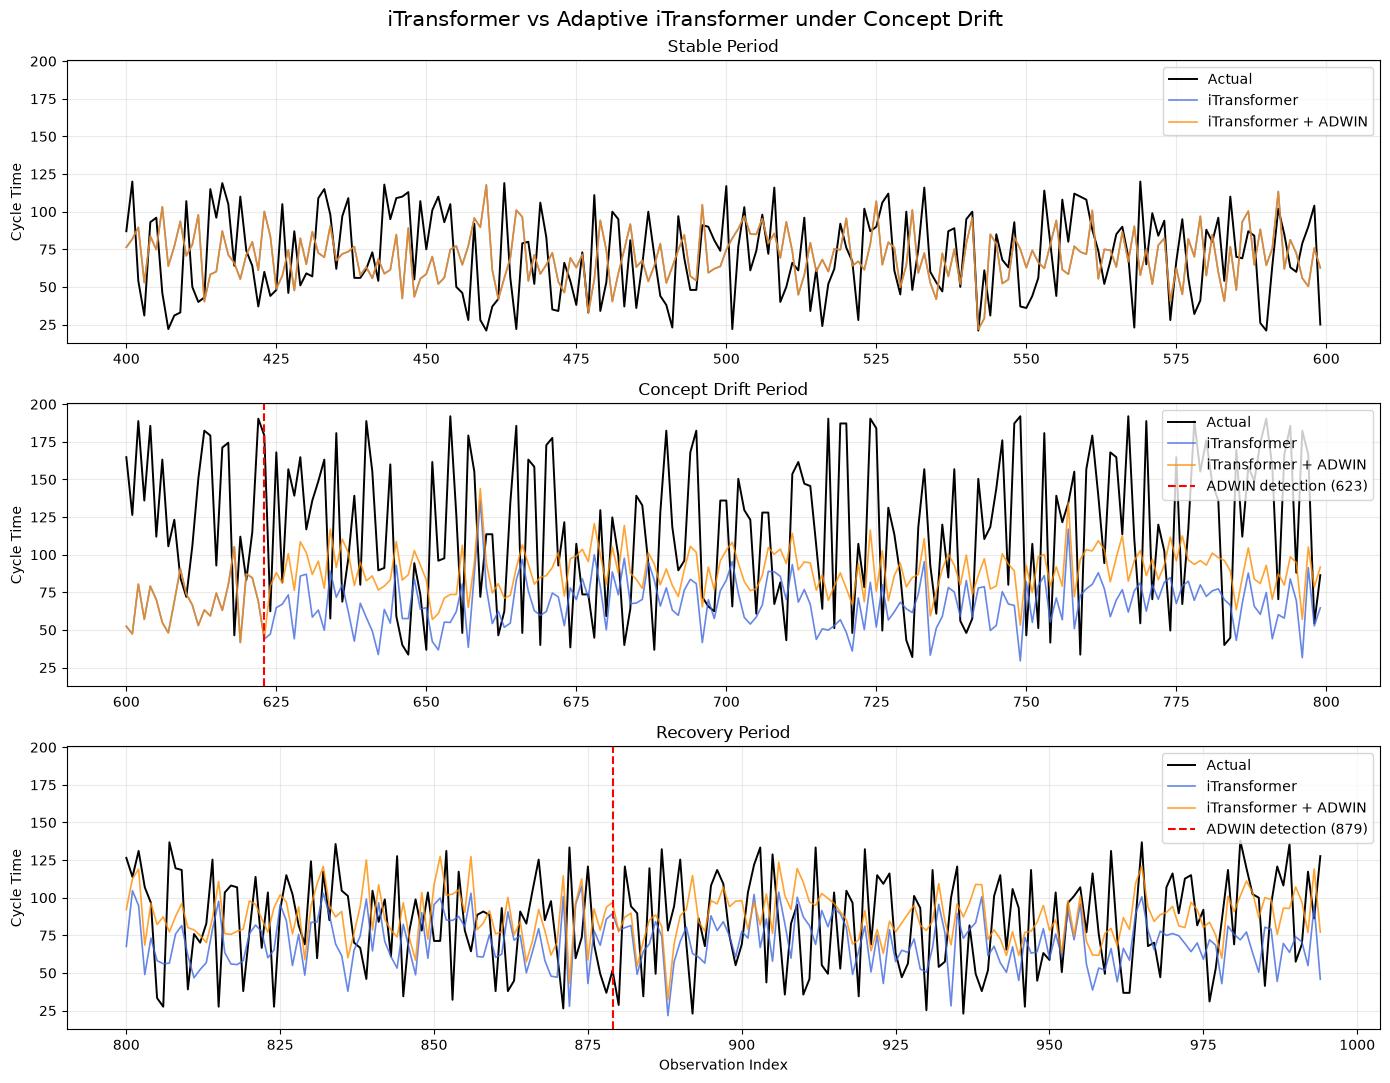

In [8]:

# Step 10: Baseline vs Adaptive iTransformer predictions

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3, 1, figsize=(14, 11),
    sharey=True
)

period_config = [
    ("Stable Period", 400, 600),
    ("Concept Drift Period", 600, 800),
    ("Recovery Period", 800, 995)
]

for ax, (title, start, end) in zip(
    axes, period_config
):
    subset = comparison_df[
        (comparison_df["Index"] >= start) &
        (comparison_df["Index"] < end)
    ]

    ax.plot(
        subset["Index"],
        subset["Actual"],
        color="black",
        linewidth=1.4,
        label="Actual"
    )

    ax.plot(
        subset["Index"],
        subset["Predicted_Baseline"],
        color="royalblue",
        linewidth=1.2,
        alpha=0.8,
        label="iTransformer"
    )

    ax.plot(
        subset["Index"],
        subset["Predicted_Adaptive"],
        color="darkorange",
        linewidth=1.2,
        alpha=0.8,
        label="iTransformer + ADWIN"
    )

    for point in adaptive_drift_points:
        if start <= point < end:
            ax.axvline(
                point,
                color="red",
                linestyle="--",
                linewidth=1.5,
                label=f"ADWIN detection ({point})"
            )

    ax.set_title(title)
    ax.set_ylabel("Cycle Time")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Observation Index")

fig.suptitle(
    "iTransformer vs Adaptive iTransformer under Concept Drift",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "Results/iTransformer_ADWIN/"
    "baseline_vs_adaptive.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


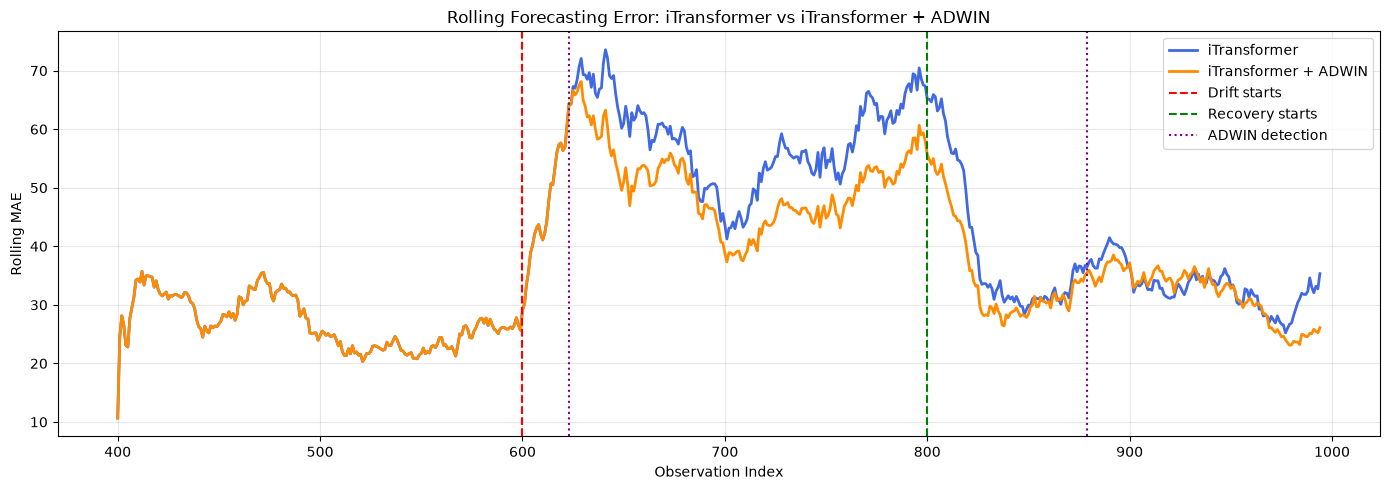

In [9]:

# Step 11: Rolling MAE comparison

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

comparison_df = comparison_df.sort_values(
    "Index"
).copy()

comparison_df["Baseline_Error"] = np.abs(
    comparison_df["Actual"]
    - comparison_df["Predicted_Baseline"]
)

comparison_df["Adaptive_Error"] = np.abs(
    comparison_df["Actual"]
    - comparison_df["Predicted_Adaptive"]
)

# Rolling MAE over 30 observations
comparison_df["Baseline_Rolling_MAE"] = (
    comparison_df["Baseline_Error"]
    .rolling(30, min_periods=1)
    .mean()
)

comparison_df["Adaptive_Rolling_MAE"] = (
    comparison_df["Adaptive_Error"]
    .rolling(30, min_periods=1)
    .mean()
)

plt.figure(figsize=(14, 5))

plt.plot(
    comparison_df["Index"],
    comparison_df["Baseline_Rolling_MAE"],
    label="iTransformer",
    color="royalblue",
    linewidth=2
)

plt.plot(
    comparison_df["Index"],
    comparison_df["Adaptive_Rolling_MAE"],
    label="iTransformer + ADWIN",
    color="darkorange",
    linewidth=2
)

plt.axvline(
    600, color="red", linestyle="--",
    label="Drift starts"
)

plt.axvline(
    800, color="green", linestyle="--",
    label="Recovery starts"
)

for j, point in enumerate(adaptive_drift_points):
    plt.axvline(
        point,
        color="purple",
        linestyle=":",
        linewidth=1.5,
        label="ADWIN detection" if j == 0 else None
    )

plt.xlabel("Observation Index")
plt.ylabel("Rolling MAE")
plt.title(
    "Rolling Forecasting Error: "
    "iTransformer vs iTransformer + ADWIN"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Results/iTransformer_ADWIN/"
    "rolling_mae_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
